# Analisis Korelasi — Data Incident (Eksplorasi Umum)

Input: `Data_Incident_clean.csv` (hasil `preprocessing_data_incident.ipynb`).

Data didominasi variabel **kategorik** dengan n kecil (62 baris), sehingga metode dipilih per jenis pasangan
(semua berskala 0–1 agar dapat digabung dalam satu matriks):

| Pasangan | Ukuran asosiasi | Uji signifikansi |
|---|---|---|
| numerik – numerik | \|Spearman ρ\| | uji Spearman |
| kategorik – kategorik | Cramér's V (bias-corrected) | Chi-square (Fisher exact untuk 2×2) |
| numerik – kategorik | Correlation ratio η | Kruskal-Wallis |

P-value dikoreksi dengan **FDR Benjamini-Hochberg** karena banyak uji dilakukan sekaligus.

> Asosiasi ≠ sebab-akibat. Dengan n = 62, hasil bersifat eksploratif.

In [1]:
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

df = pd.read_csv("Data_Incident_clean.csv")
print(df.shape)

(62, 42)


## 1. Pemilihan variabel

Dikeluarkan:
- **Identitas / teks bebas / hampir unik**: nomor insiden, nama, NIK, supervisor, dept head, deskripsi, lokasi,
  tanggal, jam mulai/selesai, periode, kolom faktor & tindakan (teks).
- **Turunan langsung**: `tipe_kecelakaan` (sudah dipecah menjadi `kategori_insiden` + `tingkat_insiden`).
- **Konstan**: dibuang otomatis (mis. `kode_unit`, `lost_worked_days`).

In [2]:
NUM_COLS = [
    "jam_kejadian", "lag_pelaporan_hari", "bulan", "tahun",
    "n_tindakan_tidak_aman", "n_kondisi_tidak_aman", "n_faktor_pribadi",
    "n_faktor_pekerjaan", "n_tindakan_perbaikan",
]
CAT_COLS = [
    "department", "jabatan", "kategori_insiden", "tingkat_insiden", "is_injury",
    "shift", "hari_kejadian", "is_weekend", "status_investigasi", "status_capa",
    "source", "jenis_laporan", "ada_korban_teridentifikasi",
]
CANDIDATE_CONSTANT = ["kode_unit", "lost_worked_days"]

data = df[NUM_COLS + CAT_COLS].copy()

# Buang kolom konstan
const = [c for c in data.columns if data[c].nunique(dropna=True) <= 1]
const += [c for c in CANDIDATE_CONSTANT if c in df and df[c].nunique(dropna=True) <= 1]
print("Kolom konstan (dibuang):", sorted(set(const)))
data = data.drop(columns=[c for c in const if c in data.columns])
NUM_COLS = [c for c in NUM_COLS if c in data.columns]
CAT_COLS = [c for c in CAT_COLS if c in data.columns]
print("Numerik :", NUM_COLS)
print("Kategorik:", CAT_COLS)

Kolom konstan (dibuang): ['kode_unit', 'lost_worked_days']
Numerik : ['jam_kejadian', 'lag_pelaporan_hari', 'bulan', 'tahun', 'n_tindakan_tidak_aman', 'n_kondisi_tidak_aman', 'n_faktor_pribadi', 'n_faktor_pekerjaan', 'n_tindakan_perbaikan']
Kategorik: ['department', 'jabatan', 'kategori_insiden', 'tingkat_insiden', 'is_injury', 'shift', 'hari_kejadian', 'is_weekend', 'status_investigasi', 'status_capa', 'source', 'jenis_laporan', 'ada_korban_teridentifikasi']


## 2. Persiapan kategori

- Variabel kategorik yang hampir konstan (total kategori minoritas < 5) dibuang.
- Nilai kosong kategorik → `"Unknown"` (untuk `tingkat_insiden` → `"Tanpa tingkat"`).
- Kategori dengan frekuensi < 5 digabung menjadi `"Lainnya"` agar tabel kontingensi tidak terlalu jarang.

In [3]:
MIN_FREQ = 5

data["tingkat_insiden"] = data["tingkat_insiden"].fillna("Tanpa tingkat")
for c in CAT_COLS:
    s = data[c].astype("string").fillna("Unknown")
    vc = s.value_counts()
    rare = vc[vc < MIN_FREQ].index
    if len(rare) > 1:            # gabung hanya jika ada >1 kategori jarang
        s = s.where(~s.isin(rare), "Lainnya")
    data[c] = s.astype("category")

# Buang kategorik yang (hampir) konstan: kategori minoritas < MIN_FREQ
for c in list(CAT_COLS):
    vc = data[c].value_counts()
    if len(vc) <= 1 or vc.iloc[1:].sum() < MIN_FREQ:
        print("Hampir konstan, dibuang:", c, dict(vc))
        CAT_COLS.remove(c)
        data = data.drop(columns=c)

pd.DataFrame({
    "n_kategori": [data[c].nunique() for c in CAT_COLS],
    "kategori": [", ".join(f"{k} ({v})" for k, v in data[c].value_counts().items()) for c in CAT_COLS],
}, index=CAT_COLS)

Hampir konstan, dibuang: status_investigasi {'Closed': np.int64(61), 'Open': np.int64(1)}


,n_kategori,kategori
department,8,"Contractor / Outsourcing (12), Process & Produ..."
jabatan,4,"Unknown (31), Lainnya (16), Operator (9), Help..."
kategori_insiden,5,"Medical Treatment Injury (MTI) (23), Fire Inci..."
tingkat_insiden,4,"Tanpa tingkat (31), LOW (25), Nearmiss HIPO (5..."
is_injury,2,"False (31), True (31)"
shift,3,"Shift 1 (07-15) (31), Shift 2 (15-23) (18), Sh..."
hari_kejadian,7,"Selasa (16), Kamis (11), Rabu (9), Sabtu (8), ..."
is_weekend,2,"False (49), True (13)"
status_capa,2,"Closed (56), Lainnya (6)"
source,3,"Web (50), Unknown (8), Android (4)"


## 3. Fungsi ukuran asosiasi

In [4]:
def cramers_v(x, y):
    """Cramér's V dengan koreksi bias (Bergsma, 2013) + p-value."""
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan, np.nan
    chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)
    if ct.shape == (2, 2):
        p = stats.fisher_exact(ct.values)[1]
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = chi2 / n
    phi2_corr = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    denom = min(k_corr - 1, r_corr - 1)
    v = np.sqrt(phi2_corr / denom) if denom > 0 else np.nan
    return v, p


def correlation_ratio(cat, num):
    """Correlation ratio η (0–1) + p-value Kruskal-Wallis."""
    mask = num.notna() & cat.notna()
    cat, num = cat[mask], num[mask].astype(float)
    groups = [num[cat == g].values for g in cat.unique()]
    groups = [g for g in groups if len(g) > 0]
    if len(groups) < 2 or num.var() == 0:
        return np.nan, np.nan
    grand = num.mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total = ((num - grand) ** 2).sum()
    eta = np.sqrt(ss_between / ss_total)
    try:
        p = stats.kruskal(*groups).pvalue
    except ValueError:
        p = np.nan
    return eta, p


def spearman(x, y):
    mask = x.notna() & y.notna()
    if mask.sum() < 3 or x[mask].nunique() < 2 or y[mask].nunique() < 2:
        return np.nan, np.nan, np.nan
    rho, p = stats.spearmanr(x[mask], y[mask])
    return abs(rho), p, rho


def association(a, b):
    """Kembalikan (nilai 0–1, p-value, metode, arah ρ jika numerik-numerik)."""
    a_num, b_num = a in NUM_COLS, b in NUM_COLS
    if a_num and b_num:
        v, p, rho = spearman(data[a], data[b])
        return v, p, "Spearman |ρ|", rho
    if not a_num and not b_num:
        v, p = cramers_v(data[a], data[b])
        return v, p, "Cramér's V", np.nan
    cat, num = (a, b) if b_num else (b, a)
    v, p = correlation_ratio(data[cat], data[num])
    return v, p, "η (corr. ratio)", np.nan

## 4. Hitung matriks asosiasi semua pasangan

In [5]:
cols = NUM_COLS + CAT_COLS
assoc = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
rows = []
for a, b in itertools.combinations(cols, 2):
    v, p, method, rho = association(a, b)
    assoc.loc[a, b] = assoc.loc[b, a] = v
    rows.append({"var_1": a, "var_2": b, "metode": method, "asosiasi": v, "rho_bertanda": rho, "p_value": p})

pairs = pd.DataFrame(rows)

# Koreksi FDR Benjamini-Hochberg
valid = pairs["p_value"].notna()
pairs.loc[valid, "p_fdr"] = stats.false_discovery_control(pairs.loc[valid, "p_value"], method="bh")
pairs["signifikan_fdr_0.05"] = pairs["p_fdr"] < 0.05

print("Jumlah pasangan diuji:", len(pairs))
print("Signifikan (p < 0.05, belum koreksi):", (pairs["p_value"] < 0.05).sum())
print("Signifikan setelah FDR:", pairs["signifikan_fdr_0.05"].sum())

Jumlah pasangan diuji: 210
Signifikan (p < 0.05, belum koreksi): 34
Signifikan setelah FDR: 23


In [6]:
# Validasi matriks
m = assoc.values.astype(float)
checks = {
    "simetris": np.allclose(m, m.T, equal_nan=True),
    "diagonal = 1": np.allclose(np.diag(m), 1),
    "nilai dalam [0, 1]": bool(np.nanmin(m) >= 0 and np.nanmax(m) <= 1 + 1e-9),
    "jumlah NaN": int(np.isnan(m).sum()),
}
pd.Series(checks, name="hasil").to_frame()

,hasil
simetris,True
diagonal = 1,True
"nilai dalam [0, 1]",True
jumlah NaN,0


## 5. Heatmap asosiasi

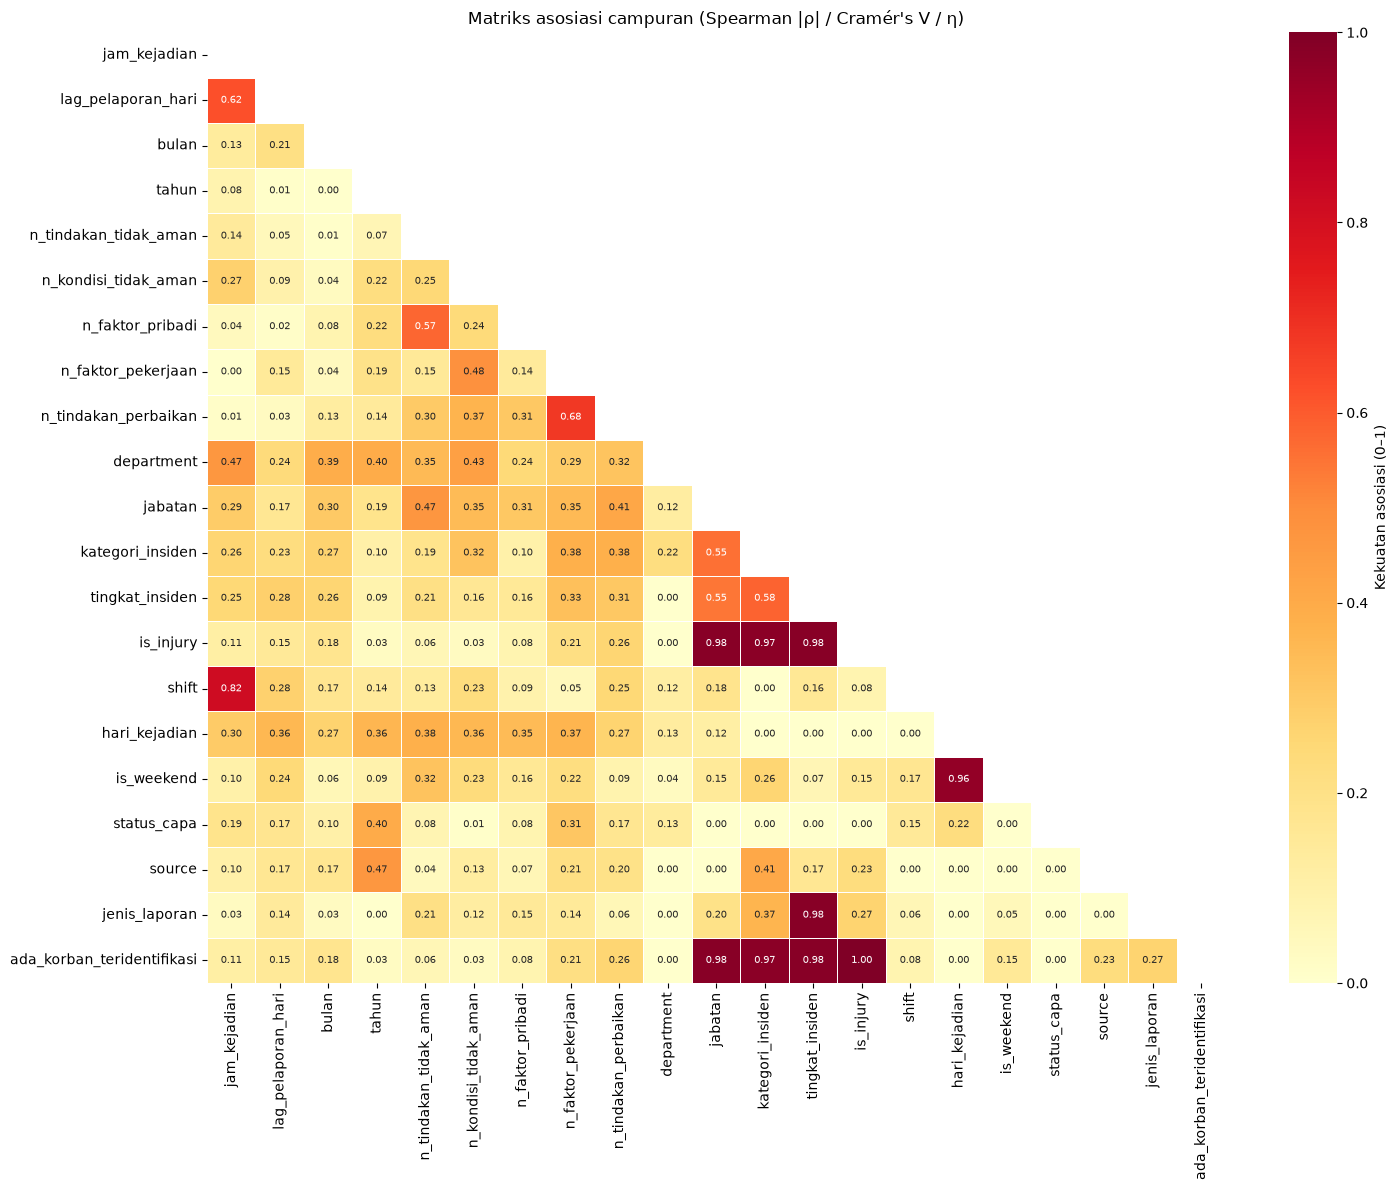

In [7]:
mask_upper = np.triu(np.ones_like(m, dtype=bool))
plt.figure(figsize=(15, 12))
sns.heatmap(assoc.astype(float), mask=mask_upper, cmap="YlOrRd", vmin=0, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.4,
            cbar_kws={"label": "Kekuatan asosiasi (0–1)"})
plt.title("Matriks asosiasi campuran (Spearman |ρ| / Cramér's V / η)")
plt.tight_layout()
plt.show()

## 6. Pasangan dengan asosiasi terkuat

Kolom `catatan` menandai pasangan yang berhubungan **secara struktural** (satu diturunkan dari yang lain),
sehingga korelasinya tinggi dengan sendirinya dan bukan temuan.

In [8]:
# Kelompok variabel yang saling terkait karena definisi/cara pencatatan:
# - data korban (nama, jabatan) hanya diisi untuk insiden cedera (MTI/FAI/LTI)
# - tingkat (LOW/MEDIUM/HIPO) hanya ada untuk Fire/Environmental/Property
# - nomor NMS (Near Miss) = tingkat "Nearmiss HIPO"
STRUCTURAL_GROUPS = [
    {"is_injury", "kategori_insiden", "tingkat_insiden", "ada_korban_teridentifikasi", "jabatan", "jenis_laporan"},
    {"shift", "jam_kejadian"},
    {"is_weekend", "hari_kejadian"},
]
STRUCTURAL = {frozenset(p) for g in STRUCTURAL_GROUPS for p in itertools.combinations(g, 2)}

def kekuatan(v):
    if pd.isna(v):
        return np.nan
    return "sangat kuat" if v >= 0.7 else "kuat" if v >= 0.5 else "sedang" if v >= 0.3 else "lemah"

pairs["kekuatan"] = pairs["asosiasi"].map(kekuatan)
pairs["catatan"] = [
    "struktural (turunan)" if frozenset({a, b}) in STRUCTURAL else ""
    for a, b in zip(pairs["var_1"], pairs["var_2"])
]

top = (pairs.sort_values("asosiasi", ascending=False)
            .loc[:, ["var_1", "var_2", "metode", "asosiasi", "rho_bertanda", "p_value", "p_fdr",
                     "signifikan_fdr_0.05", "kekuatan", "catatan"]]
            .reset_index(drop=True))
top.head(20).style.format({"asosiasi": "{:.3f}", "rho_bertanda": "{:.3f}", "p_value": "{:.4f}", "p_fdr": "{:.4f}"})

,var_1,var_2,metode,asosiasi,rho_bertanda,p_value,p_fdr,signifikan_fdr_0.05,kekuatan,catatan
0,is_injury,ada_korban_teridentifikasi,Cramér's V,1.000,nan,0.0000,0.0000,True,sangat kuat,struktural (turunan)
1,jabatan,ada_korban_teridentifikasi,Cramér's V,0.983,nan,0.0000,0.0000,True,sangat kuat,struktural (turunan)
2,tingkat_insiden,is_injury,Cramér's V,0.983,nan,0.0000,0.0000,True,sangat kuat,struktural (turunan)
3,tingkat_insiden,jenis_laporan,Cramér's V,0.983,nan,0.0000,0.0000,True,sangat kuat,struktural (turunan)
4,tingkat_insiden,ada_korban_teridentifikasi,Cramér's V,0.983,nan,0.0000,0.0000,True,sangat kuat,struktural (turunan)
5,jabatan,is_injury,Cramér's V,0.983,nan,0.0000,0.0000,True,sangat kuat,struktural (turunan)
6,kategori_insiden,is_injury,Cramér's V,0.975,nan,0.0000,0.0000,True,sangat kuat,struktural (turunan)
7,kategori_insiden,ada_korban_teridentifikasi,Cramér's V,0.975,nan,0.0000,0.0000,True,sangat kuat,struktural (turunan)
8,hari_kejadian,is_weekend,Cramér's V,0.957,nan,0.0000,0.0000,True,sangat kuat,struktural (turunan)
9,jam_kejadian,shift,η (corr. ratio),0.818,nan,0.0000,0.0000,True,sangat kuat,struktural (turunan)


In [9]:
# Temuan non-struktural: asosiasi >= 0.3 atau signifikan setelah FDR
findings = top[(top["catatan"] == "") & ((top["asosiasi"] >= 0.3) | top["signifikan_fdr_0.05"])]
print(f"{len(findings)} pasangan non-struktural dengan asosiasi >= 0.3 atau signifikan (FDR)")
findings.style.format({"asosiasi": "{:.3f}", "rho_bertanda": "{:.3f}", "p_value": "{:.4f}", "p_fdr": "{:.4f}"})

35 pasangan non-struktural dengan asosiasi >= 0.3 atau signifikan (FDR)


,var_1,var_2,metode,asosiasi,rho_bertanda,p_value,p_fdr,signifikan_fdr_0.05,kekuatan,catatan
10,n_faktor_pekerjaan,n_tindakan_perbaikan,Spearman |ρ|,0.677,0.677,0.0000,0.0000,True,kuat,
11,jam_kejadian,lag_pelaporan_hari,Spearman |ρ|,0.622,0.622,0.0000,0.0000,True,kuat,
13,n_tindakan_tidak_aman,n_faktor_pribadi,Spearman |ρ|,0.574,0.574,0.0000,0.0000,True,kuat,
16,n_kondisi_tidak_aman,n_faktor_pekerjaan,Spearman |ρ|,0.485,0.485,0.0001,0.0008,True,sedang,
17,n_tindakan_tidak_aman,jabatan,η (corr. ratio),0.472,nan,0.0437,0.2784,False,sedang,
18,tahun,source,η (corr. ratio),0.468,nan,0.0007,0.0074,True,sedang,
19,jam_kejadian,department,η (corr. ratio),0.467,nan,0.0928,0.3821,False,sedang,
20,n_kondisi_tidak_aman,department,η (corr. ratio),0.434,nan,0.1436,0.4980,False,sedang,
21,n_tindakan_perbaikan,jabatan,η (corr. ratio),0.413,nan,0.0066,0.0578,False,sedang,
22,kategori_insiden,source,Cramér's V,0.407,nan,0.0005,0.0052,True,sedang,


## 7. Detail pasangan teratas (non-struktural)


=== n_faktor_pekerjaan × n_tindakan_perbaikan | Spearman |ρ| = 0.677 | p_fdr = 0.0000 ===


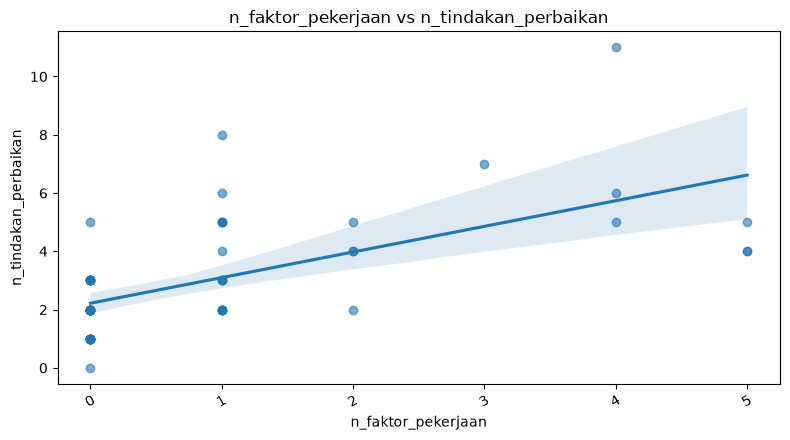


=== jam_kejadian × lag_pelaporan_hari | Spearman |ρ| = 0.622 | p_fdr = 0.0000 ===


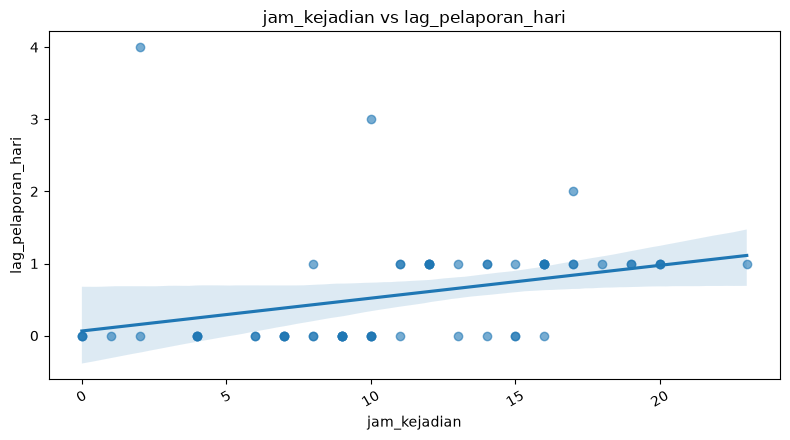


=== n_tindakan_tidak_aman × n_faktor_pribadi | Spearman |ρ| = 0.574 | p_fdr = 0.0000 ===


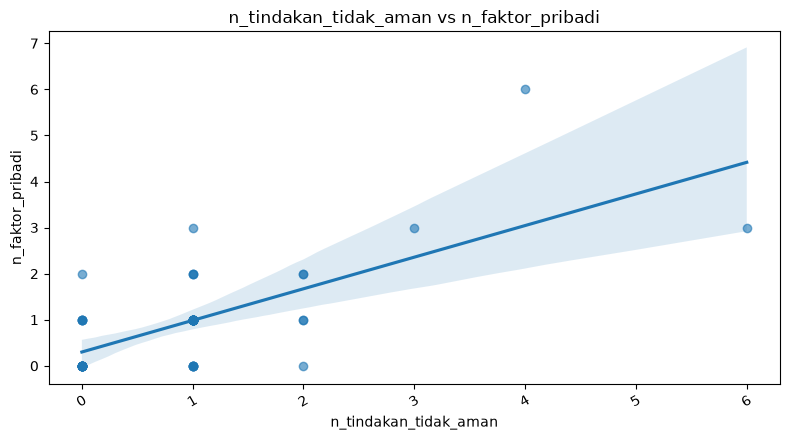


=== n_kondisi_tidak_aman × n_faktor_pekerjaan | Spearman |ρ| = 0.485 | p_fdr = 0.0008 ===


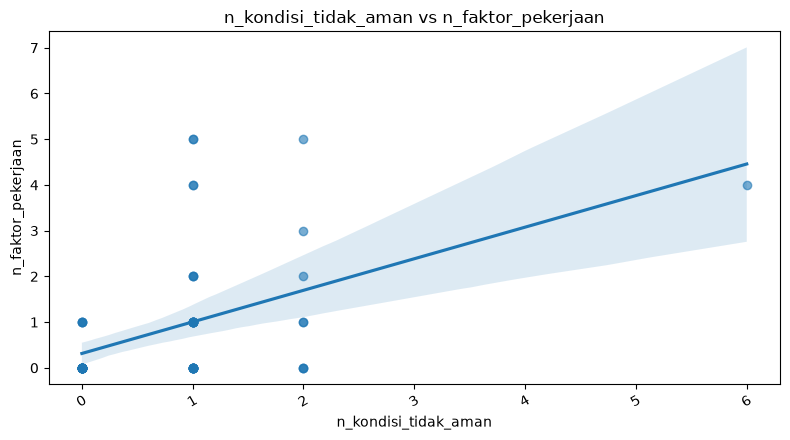


=== n_tindakan_tidak_aman × jabatan | η (corr. ratio) = 0.472 | p_fdr = 0.2784 ===


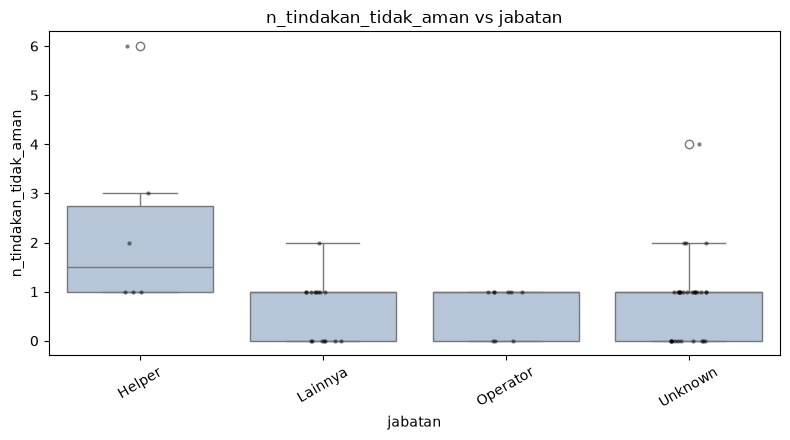

,count,mean,50%,min,max
jabatan,,,,,
Helper,6.0,2.333333,1.5,1.0,6.0
Lainnya,16.0,0.625000,1.0,0.0,2.0
Operator,9.0,0.666667,1.0,0.0,1.0
Unknown,31.0,0.838710,1.0,0.0,4.0


In [10]:
def show_pair(a, b):
    a_num, b_num = a in NUM_COLS, b in NUM_COLS
    fig, ax = plt.subplots(figsize=(8, 4.5))
    if a_num and b_num:
        sns.regplot(data=data, x=a, y=b, ax=ax, scatter_kws={"alpha": 0.6})
        out = None
    elif not a_num and not b_num:
        out = pd.crosstab(data[a], data[b], margins=True)
        pd.crosstab(data[a], data[b], normalize="index").plot(kind="bar", stacked=True, ax=ax, colormap="tab20")
        ax.set_ylabel(f"Proporsi {b}")
        ax.legend(title=b, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    else:
        cat, num = (a, b) if b_num else (b, a)
        sns.boxplot(data=data, x=cat, y=num, ax=ax, color="lightsteelblue")
        sns.stripplot(data=data, x=cat, y=num, ax=ax, color="black", alpha=0.5, size=3)
        out = data.groupby(cat, observed=True)[num].describe()[["count", "mean", "50%", "min", "max"]]
    ax.set_title(f"{a} vs {b}")
    ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.show()
    if out is not None:
        display(out)

N_DETAIL = 5
for _, r in findings.head(N_DETAIL).iterrows():
    print(f"\n=== {r.var_1} × {r.var_2} | {r.metode} = {r.asosiasi:.3f} | p_fdr = {r.p_fdr:.4f} ===")
    show_pair(r.var_1, r.var_2)

## 8. Catatan interpretasi

- **Asosiasi ≠ kausalitas.** Hasil hanya menunjukkan variabel yang cenderung muncul bersama.
- **n = 62 kecil**: tabel kontingensi bisa jarang sehingga Chi-square kurang stabil; Cramér's V versi koreksi bias
  dipakai untuk mengurangi inflasi nilai, dan p-value sudah dikoreksi FDR. Prioritaskan pasangan yang
  **kuat dan signifikan setelah FDR**.
- Pasangan berlabel **struktural** wajar berkorelasi tinggi karena definisi atau cara pencatatan:
  `shift` diturunkan dari `jam_kejadian`; data korban/jabatan hanya diisi untuk insiden cedera;
  tingkat LOW/MEDIUM/HIPO hanya untuk Fire/Environmental/Property; nomor NMS = Nearmiss HIPO.
- `tahun` berkaitan dengan perubahan cara pencatatan (mis. kelengkapan kolom faktor), sehingga asosiasi
  dengan `tahun` bisa mencerminkan perubahan proses pelaporan, bukan pola kejadian.

## 9. Simpan hasil

In [11]:
with pd.ExcelWriter("korelasi_data_incident.xlsx") as writer:
    top.to_excel(writer, sheet_name="pasangan", index=False)
    assoc.astype(float).round(4).to_excel(writer, sheet_name="matriks")
print("Tersimpan: korelasi_data_incident.xlsx")

Tersimpan: korelasi_data_incident.xlsx
